
### Partea A – Pregătirea datelor

**A1.** Citiți `Mt_DNA_tari.csv` cu `Code` ca index. Câte valori lipsă are fiecare coloană?
Afișați doar coloanele cu valori lipsă.

**A2.** Înlocuiți valorile lipsă cu `nan_replace_df`. Verificați că nu mai rămâne nicio valoare `NaN`.

**A3.** Construiți lista `variabile_observate` (haplogrupurile, fără `Country`) și matricea `x`.
Precizați `n` (numărul de instanțe) și `m` (numărul de variabile).

In [5]:
import pandas as pd
import numpy as np
from fontTools.varLib.mutator import percents
from numpy.ma.core import cumsum

import utils as utils


dna_df = pd.read_csv("./data_in/ADN/Mt_DNA_tari.csv", index_col="Code")
numerical_variables = dna_df.columns[1:]
dna_df = utils.nan_replace_df(dna_df[numerical_variables])

dna_df.head()

,L,HV,H,H1_H3,H5,HV0_V,J,T1,T2,U2,U3,U4,U5,U,K,Eu,W,X,Alt
Code,,,,,,,,,,,,,,,,,,,
ALB,0.3,0.9,47.9,3.00,4.0,3.4,7.1,4.3,5.5,1.9,0.6,2.5,6.4,2.8,5.2,1.8,2.5,1.8,5.1
AUT,0.0,0.8,44.9,16.50,3.7,1.9,8.8,4.0,8.0,1.9,0.8,4.6,8.6,1.4,8.6,1.1,1.3,1.3,2.0
BLR,0.0,2.0,39.1,11.00,2.9,6.0,8.9,2.3,5.1,2.3,2.0,3.1,9.1,6.6,2.3,1.7,3.7,0.3,5.4
BEL,0.0,0.7,46.9,26.80,6.0,2.7,6.0,2.0,9.4,0.7,1.3,2.7,3.4,5.4,12.1,2.0,3.3,1.3,0.0
BIH,0.5,1.1,45.8,16.81,5.6,4.7,8.3,1.8,4.4,0.8,0.8,4.9,8.8,1.1,4.9,3.2,2.9,0.8,5.0



---

### Partea B – Modelul ACP

**B1.** Aplicați `acp(x)` și salvați matricea de corelație în `R.csv`. Trasați corelograma.
Care este perechea de haplogrupuri cu cea mai puternică corelație (în valoare absolută, fără diagonală)?

**B2.** Verificați numeric proprietățile modelului:
- suma valorilor proprii `alpha` este egală cu `m` (datele sunt standardizate);
- vectorii proprii sunt ortonormați: `a.T @ a ≈ I`;
- componentele `c = x_ @ a` sunt necorelate, iar varianța componentei `j` este `alpha[j]`.

Folosiți `np.allclose` pentru fiecare verificare.

**B3.** *(Găsiți problema)* Afișați `alpha.dtype`. Pe acest set de date, `acp` (care folosește
`np.linalg.eig`) întoarce valori proprii **complexe** (`+0.000j`), iar mai târziu operații precum
`nlargest` din pandas vor da eroare. Matricea de corelație este simetrică. Rescrieți funcția ca
`acp_eigh` folosind `np.linalg.eigh` și explicați de ce varianta aceasta este mai potrivită.
Atenție: `eigh` întoarce valorile proprii în ordine **crescătoare**. Folosiți `acp_eigh` în
restul exercițiilor.

**B4.** Rulați ACP pe datele **nestandardizate** (`acp_eigh(x, scal=False)`). Comparați procentul de
varianță explicat de prima componentă în cele două cazuri. Ce variabilă domină componenta 1
în cazul nestandardizat și de ce? *(Indiciu: uitați-vă la abaterile standard ale variabilelor.)*


In [6]:
dna_df = (dna_df-dna_df.mean())
dna_df = dna_df/dna_df.std(ddof=0)

corr, eigenvalues, eigenvectors = utils.acp(dna_df)

corr.to_csv('./data_out/corr.csv')
without_diag = corr - np.eye(corr.shape[0]) #np.eye matrice identitate
without_diag.round(2)
without_diag=without_diag.abs()
without_diag.round(2)

display(without_diag.round(2).head())
long=without_diag.stack().reset_index()
long.columns=["X","Y","Corr"]
long.round(2)

long.sort_values("Corr",ascending=False).iloc[0]

,L,HV,H,H1_H3,H5,HV0_V,J,T1,T2,U2,U3,U4,U5,U,K,Eu,W,X,Alt
L,0.00,0.17,0.06,0.32,0.26,0.05,0.27,0.05,0.05,0.12,0.17,0.23,0.30,0.26,0.23,0.09,0.16,0.21,0.06
HV,0.17,0.00,0.54,0.39,0.09,0.36,0.04,0.00,0.06,0.02,0.34,0.09,0.22,0.06,0.06,0.10,0.15,0.19,0.42
H,0.06,0.54,0.00,0.25,0.02,0.19,0.17,0.08,0.17,0.22,0.46,0.02,0.03,0.30,0.30,0.28,0.39,0.27,0.61
H1_H3,0.32,0.39,0.25,0.00,0.28,0.16,0.08,0.43,0.01,0.21,0.18,0.19,0.16,0.01,0.21,0.15,0.11,0.23,0.44
H5,0.26,0.09,0.02,0.28,0.00,0.25,0.08,0.03,0.13,0.09,0.18,0.35,0.14,0.04,0.09,0.08,0.08,0.01,0.04


X             U3
Y              U
Corr    0.630794
Name: 203, dtype: object

---

### Partea C – Varianța componentelor

**C1.** Construiți tabelul varianței și salvați-l în `Varianta.csv`.

**C2.** Trasați scree-plot-ul cu `plot_variance`. Câte componente rețin criteriul Kaiser, criteriul
procentului minimal de 80% și criteriul Cattell?

**C3.** Scrieți o funcție `nr_componente(alpha, procent_minimal=80)` care întoarce cele trei
valori **fără** să deseneze nimic. Testați-o pentru pragurile 70%, 80% și 90%.

**C4.** Pornind de la `main.py`, rețineți `nr_min_comp` = minimul dintre criteriile care au dat
un rezultat. De ce este nevoie să ignorăm valorile `None`?

---



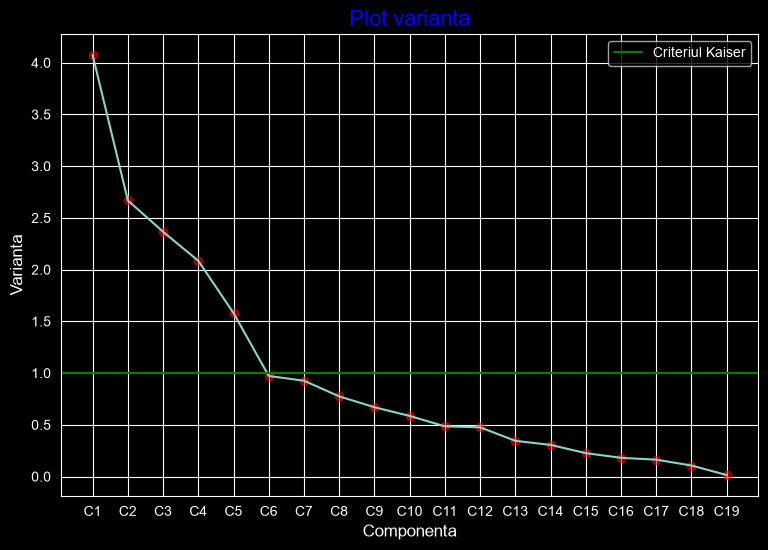

percentages =>  [0.2144119  0.1404458  0.12449981 0.10973048 0.08315569 0.0511549
 0.04873491 0.04077392 0.0352398  0.03081519 0.02551138 0.02501993
 0.01814962 0.01608379 0.01187979 0.00950633 0.00855436 0.00559242
 0.00074   ]

percentages cum sum => [0.2144119  0.3548577  0.47935751 0.58908799 0.67224368 0.72339857
 0.77213348 0.8129074  0.8481472  0.87896239 0.90447377 0.9294937
 0.94764332 0.9637271  0.97560689 0.98511322 0.99366758 0.99926
 1.        ]

percentages cum sum <0.8=> [ True  True  True  True False False False False False False False False
 False False False False False False False]



np.int64(5)

In [8]:
dna_df=pd.read_csv("./data_in/ADN/Mt_DNA_tari.csv",index_col="Code")
numerical_variables=dna_df.columns[1:]
dna_df=utils.nan_replace_df(dna_df[numerical_variables])

dna_df=(dna_df - dna_df.mean())
dna_df=dna_df/dna_df.std(ddof=0)

corr,eigenvalues,eigenvectors=utils.acp(dna_df)
dna_df.var(ddof=0).to_csv("./data_out/Varianta.csv")
utils.plot_variance(eigenvalues)

#C3
def nr_componente(alpha, procent_minimal=0.8):
    percents=alpha/alpha.sum()  #alpha -> eigenvalues
    print("percentages => ", percents)
    print()
    percents=percents.cumsum()
    print("percentages cum sum =>",percents)
    print()
    print("percentages cum sum <0.8=>",(percents<procent_minimal))
    print()
    return((percents<procent_minimal).sum()+1)

nr_componente(eigenvalues,0.6)

#C4



### Partea D – Corelații factoriale și scoruri

**D1.** Calculați componentele `c`, scorurile `s = c / sqrt(alpha)` și corelațiile factoriale
`r_xc`. Salvați `C.csv`, `S.csv`, `R_xc.csv`.

**D2.** Arătați că, pentru date standardizate, corelațiile factoriale se pot calcula și direct:
`r_xc = a * sqrt(alpha)`. Verificați cu `np.allclose`.

**D3.** Verificați că fiecare coloană din `S` are media 0 și abaterea standard 1.

**D4.** Trasați cercul corelațiilor pentru (C1, C2). Care haplogrupuri sunt bine reprezentate
(în afara cercului de rază 0.7)? Interpretați axa C1: ce haplogrupuri o definesc în sens pozitiv
și negativ?

**D5.** Trasați plotul scorurilor (C1, C2). Ce grupări de țări apar? Unde se poziționează România?


In [11]:
eigenvectors
np.sqrt(eigenvalues)

s=eigenvectors/np.sqrt(eigenvalues)








### Partea E – Indicatori de calitate

**E1.** Calculați cosinusurile pătratice. Verificați că suma pe fiecare linie este 1.
Ce țară este cel mai bine reprezentată pe C1? Dar pe planul (C1, C2)?

**E2.** Calculați contribuțiile instanțelor. Verificați că suma pe fiecare coloană este 1.
Afișați primele 3 țări care contribuie cel mai mult la varianța C1 și C2.

**E3.** Calculați comunalitățile. Verificați că, pe ultima coloană, toate comunalitățile sunt 1.
Ce haplogrup este cel mai slab explicat de primele `nr_min_comp` componente?

**E4.** Trasați corelogramele pentru cosinusuri, contribuții și comunalități (ca în `main.py`).

---

### Partea F – Harta scorurilor

**F1.** Citiți `Europa/Europa.shp` cu `geopandas`. Ce coloană folosim pentru legătura cu datele?

**F2.** Faceți `merge` între hartă și `t_c` după `Code`. Câte țări din hartă nu au date?

**F3.** Scrieți în `grafice.py` o funcție `harta(gdf, camp_legatura, t, coloana, titlu)` care
desenează o hartă choroplet pentru o componentă (țările fără date apar în gri). Trasați hărțile
pentru primele `nr_min_comp` componente și salvați-le în `graphics/`.

---

### Partea G – Extensii (opțional)

**G1.** Repetați analiza pe `Mt_DNA_Regiuni.csv`. Atenție: ultima coloană (`Mărime`, dimensiunea
eșantionului) **nu** este un haplogrup și trebuie exclusă. Fișierul nu este UTF-8, deci citiți-l cu
`encoding="latin1"`.

**G2.** Comparați rezultatele mtDNA (linia maternă) cu cele Y-DNA din `main.py` (linia paternă):
în care dintre ele se separă mai clar țările pe C1? Comparați procentul explicat de C1 și numărul
de componente reținute.

**G3.** Implementați ACP prin descompunerea în valori singulare (`np.linalg.svd` aplicat pe `x_`)
și arătați că obțineți aceleași valori proprii. De ce componentele pot avea semnul inversat?